# Exploring Game Tracking 2024

In-game player tracking for the 2024 season, sampled every 0.1 s, for the prospects in the combine data only. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). Columns are position (`x`, `y`, yds), speed (`s`, yds/s), acceleration (`a`, yds/s²), distance since last frame (`dis`, yds), orientation (`o`, deg), direction (`dir`, deg) and any play `event` tagged on that frame.

This file is large, so we skip the `time` column and use compact dtypes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## game_tracking_2024.csv

In [2]:
dtypes = {"game_id": "int64", "play_id": "int32", "nfl_id": "int32",
          "x": "float32", "y": "float32", "s": "float32", "a": "float32",
          "dis": "float32", "o": "float32", "dir": "float32", "event": "category"}
df = pd.read_csv("../data/game_tracking_2024.csv", usecols=list(dtypes), dtype=dtypes)
df.head().style.format(precision=2).set_caption("First Rows")

,game_id,play_id,nfl_id,x,y,s,a,dis,o,dir,event
0,2024080952,3379,57367,87.09,22.52,0.28,0.11,0.03,98.51,126.08,nan
1,2024080952,3379,57367,87.11,22.51,0.24,0.18,0.02,97.33,125.81,nan
2,2024080952,3379,57367,87.12,22.50,0.17,0.24,0.01,96.65,124.99,nan
3,2024080952,3379,57367,87.13,22.49,0.15,0.21,0.02,95.42,120.75,nan
4,2024080952,3379,57367,87.14,22.48,0.11,0.19,0.01,95.42,136.32,nan


In [3]:
print(len(df)) # total number of frames in dataset
print(df["nfl_id"].nunique()) # number of distinct players
print(df["game_id"].nunique()) # number of distinct games
print(df.groupby(["game_id", "play_id"]).ngroups) # number of distinct plays

7827944
318
334


40331


In [4]:
positions = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position"])
df = df.merge(positions, on="nfl_id", how="left")

masks = {
    "TE": df["combine_position"] == "TE",
    "DB": df["combine_position"] == "DB",
    "WR": df["combine_position"] == "WR",
    "DL": df["combine_position"] == "DL",
    "OL": df["combine_position"] == "OL",
}

### Coverage

In [5]:
plays_per_player = df.drop_duplicates(["game_id", "play_id", "nfl_id"]).groupby(["nfl_id", "combine_position"]).size().rename("plays").reset_index()
print(plays_per_player.groupby("combine_position")["plays"].describe())

                  count        mean         std   min     25%    50%     75%  \
combine_position                                                               
DB                 80.0  391.912500  356.818225   2.0  105.00  229.0  629.25   
DL                 69.0  323.971014  254.961702   2.0  112.00  248.0  488.00   
OL                 79.0  455.088608  429.423830   8.0  105.00  225.0  910.00   
TE                 24.0  147.333333  113.408713  12.0   57.50  138.0  181.25   
WR                 66.0  235.227273  188.038686   1.0   64.25  189.0  373.50   

                     max  
combine_position          
DB                1211.0  
DL                 936.0  
OL                1255.0  
TE                 449.0  
WR                 678.0  


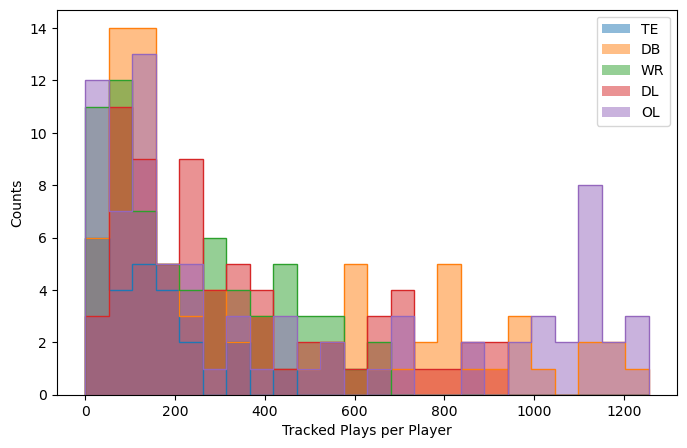

In [6]:
fig, ax = plt.subplots(figsize=(8,5))
bins = np.linspace(0, plays_per_player["plays"].max(), 25)
for i, name in enumerate(masks):
    m = plays_per_player["combine_position"] == name
    ax.hist(plays_per_player.loc[m, "plays"], bins=bins, histtype="step", color=f"C{i}")
    ax.hist(plays_per_player.loc[m, "plays"], bins=bins, histtype="stepfilled", label=name, color=f"C{i}", alpha=0.5)
ax.set_xlabel("Tracked Plays per Player")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

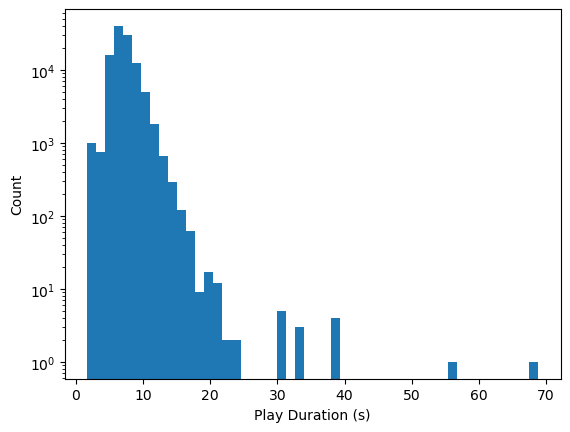

In [7]:
frames_per_play = df.groupby(["game_id", "play_id", "nfl_id"]).size() / 10
plt.hist(frames_per_play, bins=50)
plt.xlabel("Play Duration (s)")
plt.ylabel("Count")
plt.yscale("log");

### Events

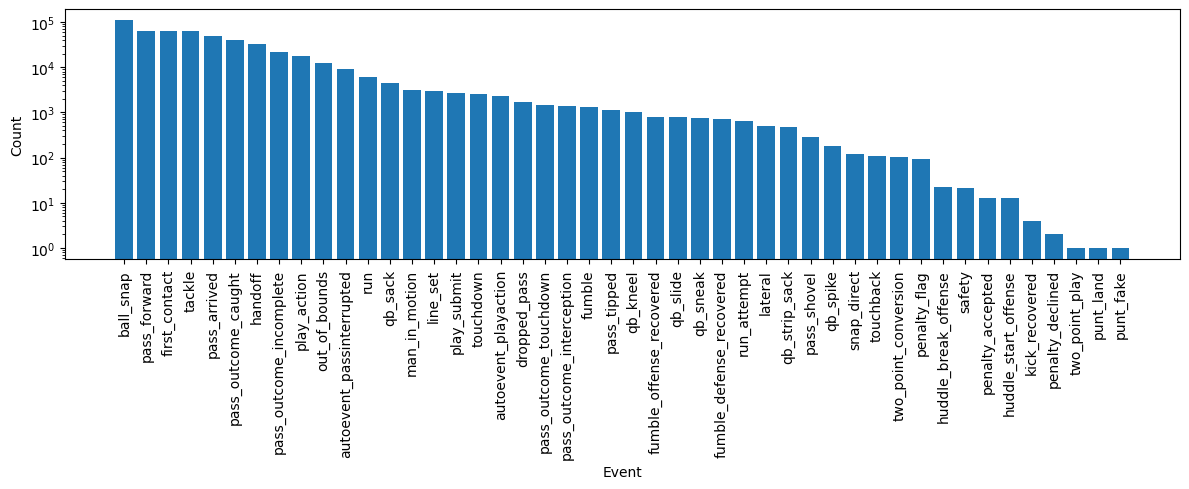

In [8]:
events = df["event"].value_counts()

fig, ax = plt.subplots(figsize=(12,5))
ax.bar(events.index.astype(str), events.values)
ax.set_xlabel("Event")
ax.set_ylabel("Count")
ax.set_yscale("log")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Kinematics

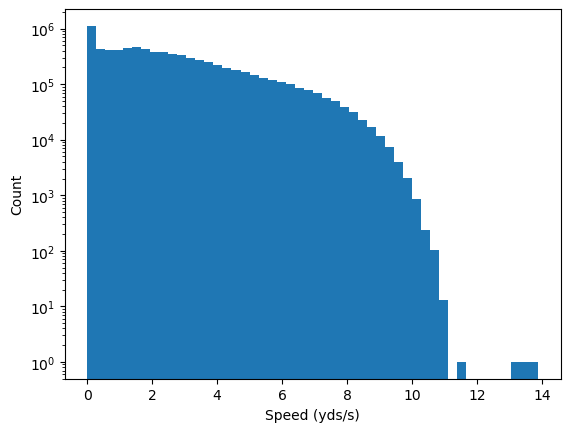

In [9]:
plt.hist(df["s"].dropna(), bins=50)
plt.xlabel("Speed (yds/s)")
plt.ylabel("Count")
plt.yscale("log");

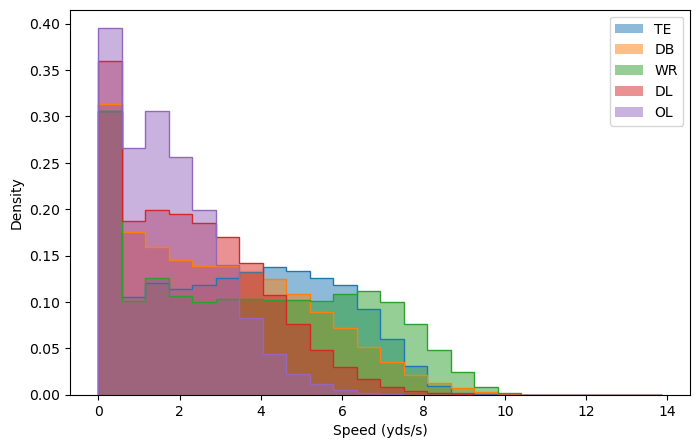

In [10]:
bins = np.linspace(df["s"].min(), df["s"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "s"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "s"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "s"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Speed (yds/s)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

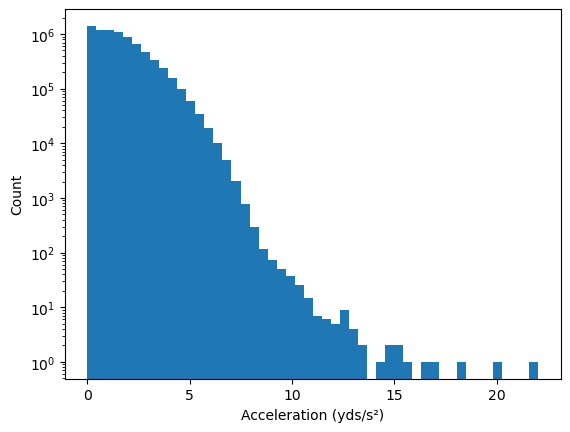

In [11]:
plt.hist(df["a"].dropna(), bins=50)
plt.xlabel("Acceleration (yds/s²)")
plt.ylabel("Count")
plt.yscale("log");

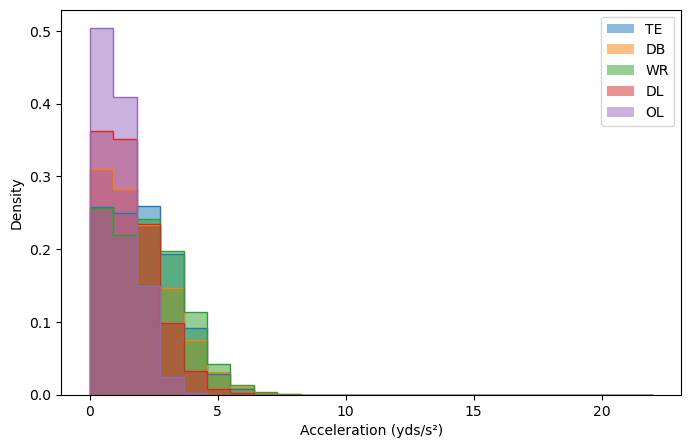

In [12]:
bins = np.linspace(df["a"].min(), df["a"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "a"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "a"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "a"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Acceleration (yds/s²)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

Each player's top in-game speed this season. Frames above ~12 yds/s are almost certainly tracking glitches, so they're cut.

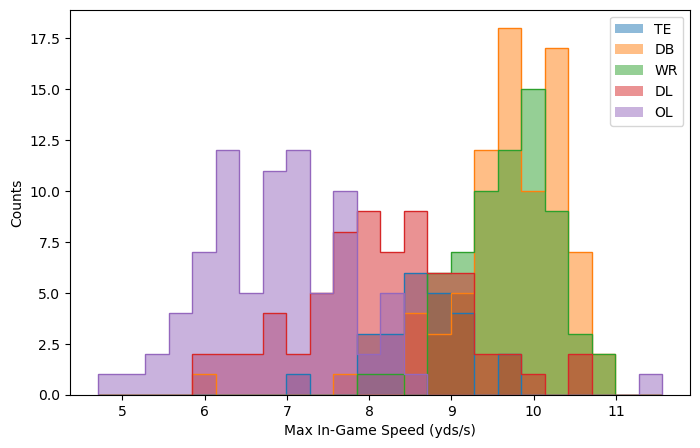

In [13]:
top_speed = df[df["s"] < 12].groupby(["nfl_id", "combine_position"])["s"].max().rename("max_speed").reset_index()

fig, ax = plt.subplots(figsize=(8,5))
bins = np.linspace(top_speed["max_speed"].min(), top_speed["max_speed"].max(), 25)
for i, name in enumerate(masks):
    m = top_speed["combine_position"] == name
    ax.hist(top_speed.loc[m, "max_speed"], bins=bins, histtype="step", color=f"C{i}")
    ax.hist(top_speed.loc[m, "max_speed"], bins=bins, histtype="stepfilled", label=name, color=f"C{i}", alpha=0.5)
ax.set_xlabel("Max In-Game Speed (yds/s)")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

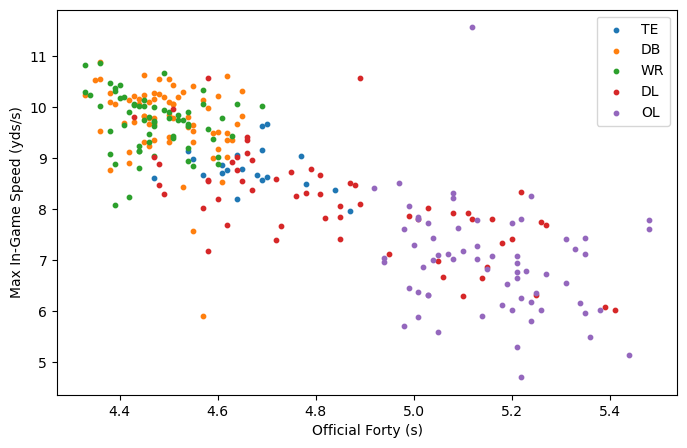

In [14]:
results = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "forty"])
top_speed = top_speed.merge(results, on="nfl_id", how="left")

fig, ax = plt.subplots(figsize=(8,5))
for i, name in enumerate(masks):
    m = top_speed["combine_position"] == name
    ax.scatter(top_speed.loc[m, "forty"], top_speed.loc[m, "max_speed"], s=10, label=name, color=f"C{i}")
ax.set_xlabel("Official Forty (s)")
ax.set_ylabel("Max In-Game Speed (yds/s)")
ax.legend()
plt.show()

### Field Position

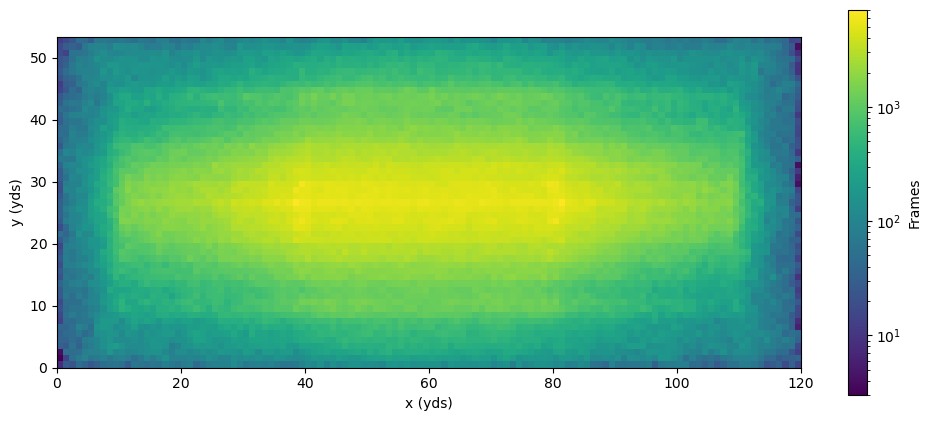

In [15]:
fig, ax = plt.subplots(figsize=(12,5))
h = ax.hist2d(df["x"], df["y"], bins=[120, 53], range=[[0, 120], [0, 53.3]], cmap="viridis", norm="log")
fig.colorbar(h[3], ax=ax, label="Frames")
ax.set_xlabel("x (yds)")
ax.set_ylabel("y (yds)")
ax.set_aspect("equal")
plt.show()

### Example Play

The prospects tracked on the play with the most of them on the field.

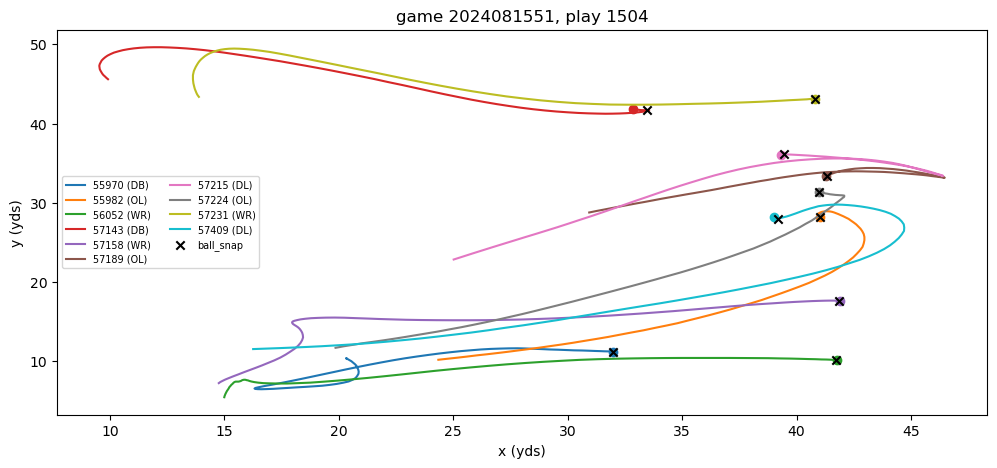

In [16]:
players_per_play = df.groupby(["game_id", "play_id"])["nfl_id"].nunique()
game_id, play_id = players_per_play.idxmax()
play = df[(df["game_id"] == game_id) & (df["play_id"] == play_id)]

fig, ax = plt.subplots(figsize=(12,5))
for nfl_id, p in play.groupby("nfl_id"):
    line, = ax.plot(p["x"], p["y"], label=f"{nfl_id} ({p['combine_position'].iloc[0]})")
    ax.scatter(p["x"].iloc[0], p["y"].iloc[0], color=line.get_color(), marker="o")
snap = play[play["event"] == "ball_snap"]
ax.scatter(snap["x"], snap["y"], color="k", marker="x", zorder=3, label="ball_snap")
ax.set_xlabel("x (yds)")
ax.set_ylabel("y (yds)")
ax.set_title(f"game {game_id}, play {play_id}")
ax.legend(fontsize=7, ncol=2)
plt.show()